In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy.linalg import solve_triangular

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

np.set_printoptions(precision=6, suppress=True)

In [2]:
results = Path("../../results/implementation")
figures = results/"figures"
tables = results/"tables"

In [3]:
df = pd.read_csv("../../data/processed/real_estate_data_updated.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (414, 8)


,X1 transaction year,X1 transaction month,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,2012,December,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012,December,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013,August,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013,July,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012,November,5.0,390.56840,5,24.97937,121.54245,43.1


In [4]:
numerical_features = [
    "X2 house age",
    "X3 distance to the nearest MRT station",
    "X4 number of convenience stores",
    "X5 latitude",
    "X6 longitude"
]

categorical_features = [
    "X1 transaction month"
]

target = "Y house price of unit area"

x_df = pd.get_dummies(
    df[numerical_features + categorical_features],
    columns=categorical_features,
    drop_first=True,
    dtype=float
)

x = x_df.to_numpy(dtype=float)
y = df[target].to_numpy(dtype=float)

feature_names = ["Intercept"] + x_df.columns.tolist()

x_design = np.column_stack([
    np.ones(x.shape[0]),
    x
])

print("Design matrix shape:", x_design.shape)
print("Target shape:", y.shape)
print("Number of features including intercept:", len(feature_names))

Design matrix shape: (414, 17)
Target shape: (414,)
Number of features including intercept: 17


In [5]:
# QR Composition

Q, R = np.linalg.qr(x_design, mode="reduced")

print("Q Shape", Q.shape)
print("R Shape", R.shape)

Q Shape (414, 17)
R Shape (17, 17)


In [6]:
# verify QR decomposition

reconstruction_error = np.linalg.norm(x_design - Q @ R)

orthogonality_error = np.linalg.norm(
    Q.T @ Q - np.eye(Q.shape[1])
)

print("Reconstruction error:", reconstruction_error)
print("Orthogonality error:", orthogonality_error)

Reconstruction error: 7.325452902333062e-12
Orthogonality error: 2.3468796699625457e-15


In [7]:
# estimate cofficient

QTy = Q.T @ y

beta_qr = solve_triangular(
    R,
    QTy,
    lower=False
)

coefficients_qr = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": beta_qr
})

display(coefficients_qr)

,Feature,Coefficient
0,Intercept,-4297.651398
1,X2 house age,-0.272789
2,X3 distance to the nearest MRT station,-0.004482
3,X4 number of convenience stores,1.153752
4,X5 latitude,233.004458
5,X6 longitude,-12.153850
6,X1 transaction month_August,2.835504
7,X1 transaction month_December,-3.014805
8,X1 transaction month_February,0.752765
9,X1 transaction month_January,-0.885104


In [8]:
# predictions and residuals

y_pred_qr = x_design @ beta_qr

residuals_qr = y - y_pred_qr

print("Predictions:", y_pred_qr[:10])
print("Residuals:", residuals_qr[:10])

Predictions: [45.725401 46.381414 49.768741 50.428735 46.657258 32.146685 39.745188
 44.235186 10.819943 32.003284]
Residuals: [-7.825401 -4.181414 -2.468741  4.371265 -3.557258 -0.046685  0.554812
  2.464814  7.980057 -9.903284]


## 7. Regression Performance Evaluation

The performance of the OLS model obtained through QR decomposition
is evaluated using the following metrics:

- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- Mean Absolute Error (MAE)
- Coefficient of Determination (R²)

These metrics provide a quantitative assessment of the model's
prediction accuracy.

In [9]:
mse_qr = mean_squared_error(y, y_pred_qr)
rmse_qr = np.sqrt(mse_qr)
mae_qr = mean_absolute_error(y, y_pred_qr)
r2_qr = r2_score(y, y_pred_qr)

metrics_qr = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "R2"],
    "QR Decomposition": [
        mse_qr,
        rmse_qr,
        mae_qr,
        r2_qr
    ]
})

display(metrics_qr)

,Metric,QR Decomposition
0,MSE,74.973033
1,RMSE,8.658697
2,MAE,6.013422
3,R2,0.594059



## 8. Numerical Stability Analysis

Numerical stability is an important consideration when solving least-squares problems.

The QR decomposition avoids explicitly forming the normal equations and uses an orthogonal factorization of the design matrix.

In this section, numerical properties of the QR-based solution are examined through:

1. Matrix rank and rank deficiency.
2. Singular values of the design matrix.
3. Condition number of the design matrix.
4. Condition number of the normal matrix.
5. Residual norm and relative residual.
6. Least-squares optimality condition.

These diagnostics help assess the numerical reliability of the computed regression coefficients.


In [10]:
rank_qr = np.linalg.matrix_rank(x_design)

number_of_columns = x_design.shape[1]
rank_deficiency_qr = number_of_columns - rank_qr

print("Number of columns:", number_of_columns)
print("Matrix rank:", rank_qr)
print("Rank deficiency:", rank_deficiency_qr)
print("Full column rank:", rank_qr == number_of_columns)

Number of columns: 17
Matrix rank: 17
Rank deficiency: 0
Full column rank: True


In [11]:
# singular value analysis

singular_values_qr = np.linalg.svd(
    x_design,
    compute_uv=False
)

print("Singular values:")
print(singular_values_qr)

print("\nLargest singular value:", singular_values_qr[0])
print("Smallest singular value:", singular_values_qr[-1])

Singular values:
[33867.718371  1933.179177   229.172926    47.578029     7.406619
     6.626126     6.469479     5.954132     5.486261     5.424706
     5.294095     5.212729     5.031603     4.826115     1.624628
     0.200364     0.001421]

Largest singular value: 33867.71837097972
Smallest singular value: 0.0014206193629536844


In [12]:
# condition numbers

condition_x_qr = np.linalg.cond(x_design)

xtx_qr = x_design.T @ x_design

condition_xtx_qr = np.linalg.cond(xtx_qr)

print("Condition number of X:", condition_x_qr)
print("Condition number of X.T @ X:", condition_xtx_qr)

Condition number of X: 23840107.52927059
Condition number of X.T @ X: 568346163503763.0


In [13]:
# residual analysis

residual_norm_qr = np.linalg.norm(residuals_qr)

y_norm = np.linalg.norm(y)

relative_residual_qr = residual_norm_qr / y_norm

print("Residual norm:", residual_norm_qr)
print("Relative residual:", relative_residual_qr)

Residual norm: 176.17841977921367
Relative residual: 0.21465161197604754


In [ ]:
# least square optimality condition

residual_norm_qr = np.linalg.norm(residuals_qr)

y_norm = np.linalg.norm(y)

relative_residual_qr = residual_norm_qr / y_norm

print("Residual norm:", residual_norm_qr)
print("Relative residual:", relative_residual_qr)

Residual norm: 176.17841977921367
Relative residual: 0.21465161197604754


In [ ]:
optimality_residual_qr = x_design.T @ residuals_qr

optimality_error_qr = np.linalg.norm(
    optimality_residual_qr
)

print("Least-squares optimality residual:")
print(optimality_residual_qr)

print("\nOptimality error:", optimality_error_qr)

Least-squares optimality residual:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Optimality error: 2.4220326107946144e-07


In [15]:
# QR diagonal analysis

diagonal_R = np.abs(np.diag(R))

print("Absolute diagonal entries of R:")
print(diagonal_R)

print("\nSmallest diagonal entry:", diagonal_R.min())
print("Largest diagonal entry:", diagonal_R.max())

Absolute diagonal entries of R:
[   20.34699    231.522644 25640.677289    47.616279     0.20094
     0.1824       4.639465     5.841363     6.189343     4.886479
     6.150386     6.55881      4.618333     4.824714     4.73859
     4.307536     3.9265  ]

Smallest diagonal entry: 0.18239957517847918
Largest diagonal entry: 25640.677288677813



## 9. Validation Against NumPy Least-Squares Solution

The QR-based coefficient estimates are validated against the solution obtained using `numpy.linalg.lstsq`.

The comparison examines:

- Estimated regression coefficients.
- Predicted values.
- Residual differences.
- Numerical rank.

The purpose is to verify that the manually implemented QR procedure produces a solution consistent with an established numerical least-squares routine.


In [16]:
beta_lstsq, residuals_lstsq, rank_lstsq, singular_values_lstsq = (
    np.linalg.lstsq(x_design, y, rcond=None)
)

coefficient_difference_qr = np.linalg.norm(
    beta_qr - beta_lstsq
)

y_pred_lstsq = x_design @ beta_lstsq

prediction_difference_qr = np.linalg.norm(
    y_pred_qr - y_pred_lstsq
)

print("QR matrix rank:", rank_qr)
print("NumPy least-squares rank:", rank_lstsq)

print("\nCoefficient difference norm:",
      coefficient_difference_qr)

print("Prediction difference norm:",
      prediction_difference_qr)

print("\nQR residual norm:",
      np.linalg.norm(y - y_pred_qr))

print("NumPy residual norm:",
      np.linalg.norm(y - y_pred_lstsq))

QR matrix rank: 17
NumPy least-squares rank: 17

Coefficient difference norm: 1.7735932229594788e-10
Prediction difference norm: 1.53962736341313e-10

QR residual norm: 176.17841977921367
NumPy residual norm: 176.178419779214


In [22]:
# coefficient comparison table

coefficient_comparison_qr = pd.DataFrame({
    "Feature": feature_names,
    "QR Coefficient": beta_qr,
    "NumPy lstsq Coefficient": beta_lstsq,
    "Absolute Difference": np.abs(beta_qr - beta_lstsq)
})

display(coefficient_comparison_qr)

,Feature,QR Coefficient,NumPy lstsq Coefficient,Absolute Difference
0,Intercept,-4297.651398,-4297.651398,1.773515e-10
1,X2 house age,-0.272789,-0.272789,1.340594e-13
2,X3 distance to the nearest MRT station,-0.004482,-0.004482,5.348152e-15
3,X4 number of convenience stores,1.153752,1.153752,3.619327e-14
4,X5 latitude,233.004458,233.004458,0.000000e+00
5,X6 longitude,-12.153850,-12.153850,1.502798e-12
6,X1 transaction month_August,2.835504,2.835504,1.212364e-13
7,X1 transaction month_December,-3.014805,-3.014805,1.434408e-13
8,X1 transaction month_February,0.752765,0.752765,2.231548e-14
9,X1 transaction month_January,-0.885104,-0.885104,3.231859e-13



## 10. Visualization and Diagnostic Plots

Graphical diagnostics are used to examine the fitted model and its numerical characteristics.

The following visualizations are generated:

1. Singular value spectrum of the design matrix.
2. Actual versus predicted house prices.
3. Residuals versus predicted values.
4. Distribution of residuals.

These visualizations provide complementary information about matrix conditioning, model fit, residual patterns and prediction errors.


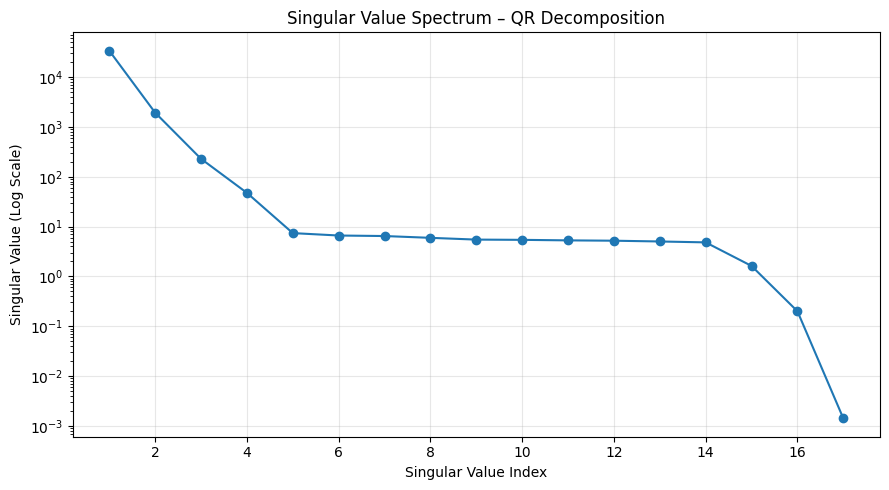

In [ ]:
# singular values

plt.figure(figsize=(9, 5))

plt.semilogy(
    np.arange(1, len(singular_values_qr) + 1),
    singular_values_qr,
    marker="o"
)

plt.xlabel("Singular Value Index")
plt.ylabel("Singular Value (Log Scale)")
plt.title("Singular Value Spectrum – QR Decomposition")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

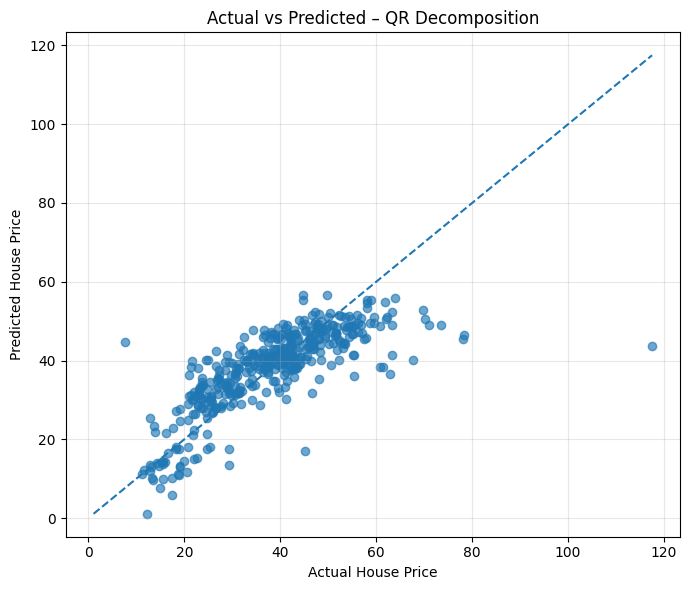

In [18]:
# actual vs predicted

plt.figure(figsize=(7, 6))

plt.scatter(y, y_pred_qr, alpha=0.65)

lower = min(y.min(), y_pred_qr.min())
upper = max(y.max(), y_pred_qr.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted – QR Decomposition")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

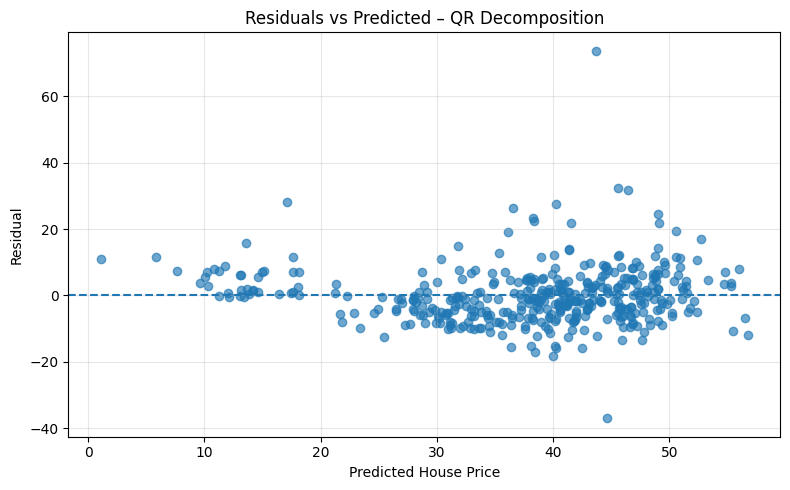

In [19]:
# residuals vs predicted

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_qr,
    residuals_qr,
    alpha=0.65
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted House Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted – QR Decomposition")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

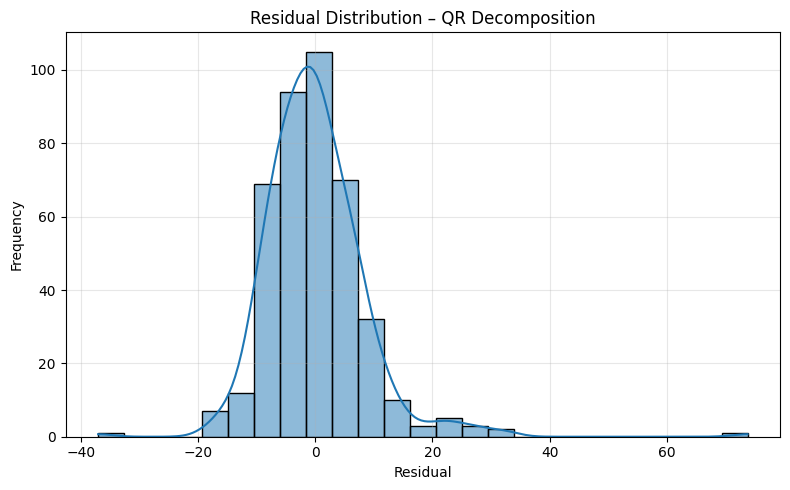

In [20]:
# residual distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    residuals_qr,
    bins=25,
    kde=True
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution – QR Decomposition")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 11. Numerical Diagnostics Summary

This section consolidates the regression performance and numerical stability measures obtained from the QR-based OLS implementation.

The summary provides a compact record of the model's predictive performance, matrix conditioning, rank and numerical validation.


In [24]:
diagnostics_qr = pd.DataFrame({
    "Diagnostic": [
        "Number of observations",
        "Number of design matrix columns",
        "Matrix rank",
        "Rank deficiency",
        "Condition number of X",
        "Condition number of X.T @ X",
        "Largest singular value",
        "Smallest singular value",
        "Reconstruction error",
        "Orthogonality error",
        "Residual norm",
        "Relative residual",
        "Least-squares optimality error",
        "Coefficient difference from lstsq",
        "Prediction difference from lstsq"
    ],
    "Value": [
        x_design.shape[0],
        x_design.shape[1],
        rank_qr,
        rank_deficiency_qr,
        condition_x_qr,
        condition_xtx_qr,
        singular_values_qr[0],
        singular_values_qr[-1],
        reconstruction_error,
        orthogonality_error,
        residual_norm_qr,
        relative_residual_qr,
        optimality_error_qr,
        coefficient_difference_qr,
        prediction_difference_qr
    ]
})

display(diagnostics_qr)

,Diagnostic,Value
0,Number of observations,4.140000e+02
1,Number of design matrix columns,1.700000e+01
2,Matrix rank,1.700000e+01
3,Rank deficiency,0.000000e+00
4,Condition number of X,2.384011e+07
5,Condition number of X.T @ X,5.683462e+14
6,Largest singular value,3.386772e+04
7,Smallest singular value,1.420619e-03
8,Reconstruction error,7.325453e-12
9,Orthogonality error,2.346880e-15



## 12. Final Results and Export

All numerical outputs and diagnostic figures generated in this notebook are saved to the designated results directory.

The exported files include regression coefficients, predictions, residuals, evaluation metrics, numerical diagnostics, and graphical visualizations.

Existing files with identical names are overwritten when the notebook is executed again.


In [25]:
coefficients_qr.to_csv(
    tables / "ols_qr_coefficients.csv",
    index=False
)

predictions_qr = pd.DataFrame({
    "Actual": y,
    "Predicted": y_pred_qr,
    "Residual": residuals_qr
})

predictions_qr.to_csv(
    tables / "ols_qr_predictions.csv",
    index=False
)

metrics_qr.to_csv(
    tables / "ols_qr_metrics.csv",
    index=False
)

diagnostics_qr.to_csv(
    tables / "ols_qr_diagnostics.csv",
    index=False
)

coefficient_comparison_qr.to_csv(
    tables / "ols_qr_numpy_validation.csv",
    index=False
)

singular_values_table_qr = pd.DataFrame({
    "Singular Value Index": np.arange(1, len(singular_values_qr) + 1),
    "Singular Value": singular_values_qr
})

singular_values_table_qr.to_csv(
    tables / "ols_qr_singular_values.csv",
    index=False
)


# Feature names

pd.DataFrame({
    "Feature": feature_names
}).to_csv(
    tables / "ols_qr_feature_names.csv",
    index=False
)

print("All QR numerical results exported successfully.")

All QR numerical results exported successfully.


In [26]:
# figures saved

# singular values

plt.figure(figsize=(9, 5))

plt.semilogy(
    np.arange(1, len(singular_values_qr) + 1),
    singular_values_qr,
    marker="o"
)

plt.xlabel("Singular Value Index")
plt.ylabel("Singular Value (Log Scale)")
plt.title("Singular Value Spectrum – QR Decomposition")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures / "ols_qr_singular_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# Actual vs predicted

plt.figure(figsize=(7, 6))

plt.scatter(y, y_pred_qr, alpha=0.65)

lower = min(y.min(), y_pred_qr.min())
upper = max(y.max(), y_pred_qr.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted – QR Decomposition")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures / "ols_qr_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# Residuals vs predicted

plt.figure(figsize=(8, 5))

plt.scatter(y_pred_qr, residuals_qr, alpha=0.65)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted – QR Decomposition")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures / "ols_qr_residuals_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# Residual distribution

plt.figure(figsize=(8, 5))

sns.histplot(residuals_qr, bins=25, kde=True)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution – QR Decomposition")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures / "ols_qr_residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("All QR figures exported successfully.")

All QR figures exported successfully.
